<a href="https://colab.research.google.com/github/dmunsyzbaev-dot/coffee/blob/main/Zerthanalyk_02_Google_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# №2 зертханалық жұмыс — Әртүрлі көздерден деректер жинау


In [ ]:
!pip -q install pyarrow openpyxl missingno rapidfuzz plotly beautifulsoup4 requests statsmodels scikit-learn umap-learn wordcloud shap imbalanced-learn

In [ ]:
import os, sys, time, json, sqlite3, warnings, pathlib, logging, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('reports', exist_ok=True)
os.makedirs('src', exist_ok=True)

RNG = np.random.default_rng(42)
np.random.seed(42)
warnings.filterwarnings('ignore')

n = 8000
customers = RNG.integers(1, 1101, n)
products = RNG.integers(1, 31, n)

df = pd.DataFrame({
    'order_id': np.arange(1, n + 1),
    'customer_id': customers,
    'product_id': products,
    'date': pd.Timestamp('2024-01-01') + pd.to_timedelta(RNG.integers(0, 730, n), unit='D'),
    'city': RNG.choice(['Almaty', 'Astana', 'Shymkent', 'Karaganda'], n),
    'category': RNG.choice(['Electronics', 'Clothing', 'Food', 'Home'], n),
    'quantity': RNG.integers(1, 7, n),
    'unit_price': np.round(RNG.lognormal(8.1, 0.65, n), 2),
    'discount': RNG.choice([0, 0.05, 0.10, 0.20], n),
    'age': RNG.integers(18, 71, n),
    'channel': RNG.choice(['web', 'app', 'store'], n),
    'rating': RNG.integers(1, 6, n)
})

df['amount'] = (df.quantity * df.unit_price * (1 - df.discount)).round(2)
df['returned'] = (RNG.random(n) < (0.06 + 0.035 * (df.rating <= 2))).astype(int)
df['review'] = np.where(df.rating >= 4, 'great quality fast delivery', np.where(df.rating <= 2, 'bad quality slow delivery', 'average product delivery'))
df.loc[RNG.choice(n, 120, replace=False), 'age'] = np.nan

df.to_csv('data/raw/dataset.csv', index=False)
print('Данные успешно сгенерированы. Размер датасета:', df.shape)
display(df.head())


Данные успешно сгенерированы. Размер датасета: (8000, 15)


,order_id,customer_id,product_id,date,city,category,quantity,unit_price,discount,age,channel,rating,amount,returned,review
0,1,99,20,2025-12-28,Karaganda,Food,6,2886.58,0.05,61.0,app,2,16453.51,0,bad quality slow delivery
1,2,852,22,2025-02-12,Shymkent,Food,5,3761.36,0.10,58.0,app,3,16926.12,0,average product delivery
2,3,721,9,2024-01-29,Shymkent,Home,2,2056.07,0.00,42.0,store,4,4112.14,0,great quality fast delivery
3,4,483,11,2025-10-17,Astana,Clothing,6,4272.71,0.20,30.0,web,3,20509.01,0,average product delivery
4,5,477,29,2025-11-24,Karaganda,Home,6,4914.91,0.00,59.0,store,5,29489.46,0,great quality fast delivery


## 1-тапсырма. CSV, Excel және JSON

**Мақсат:** csv, excel және json әдісін практикалық деректермен көрсету. Кодтарды ретімен орындаңыз.

In [ ]:
df.head(100).to_csv('data/raw/sample_semicolon.csv',sep=';',index=False); display(pd.read_csv('data/raw/sample_semicolon.csv',sep=';').head())

,order_id,customer_id,product_id,date,city,category,quantity,unit_price,discount,age,channel,rating,amount,returned,review
0,1,99,20,2025-12-28,Karaganda,Food,6,2886.58,0.05,61.0,app,2,16453.51,0,bad quality slow delivery
1,2,852,22,2025-02-12,Shymkent,Food,5,3761.36,0.10,58.0,app,3,16926.12,0,average product delivery
2,3,721,9,2024-01-29,Shymkent,Home,2,2056.07,0.00,42.0,store,4,4112.14,0,great quality fast delivery
3,4,483,11,2025-10-17,Astana,Clothing,6,4272.71,0.20,30.0,web,3,20509.01,0,average product delivery
4,5,477,29,2025-11-24,Karaganda,Home,6,4914.91,0.00,59.0,store,5,29489.46,0,great quality fast delivery


In [ ]:
work = df.copy()
print('Типтер және бос мәндер')
display(pd.DataFrame({'type':work.dtypes.astype(str),'missing':work.isna().sum(),'unique':work.nunique()}))

Типтер және бос мәндер


,type,missing,unique
order_id,int64,0,8000
customer_id,int64,0,1099
product_id,int64,0,30
date,datetime64[ns],0,730
city,object,0,4
category,object,0,4
quantity,int64,0,6
unit_price,float64,0,7946
discount,float64,0,4
age,float64,120,53


In [ ]:
# CSV, Excel және JSON: тексерілетін көрсеткіштер
print('Жазбалар:',len(df),'| Бос мәндер:',int(df.isna().sum().sum()))
print('Сома медианасы:',round(df.amount.median(),2),'| Орташа:',round(df.amount.mean(),2))

Жазбалар: 8000 | Бос мәндер: 120
Сома медианасы: 9550.05 | Орташа: 13335.69


In [ ]:
# CSV, Excel және JSON: топтар арасындағы сандық айырмашылық
g=df.groupby('city').amount.agg(['count','mean','median','std']).round(2);display(g)
print('Макс/мин орташа қатынасы:',round(g['mean'].max()/g['mean'].min(),3))

,count,mean,median,std
city,,,,
Almaty,2008,13628.25,9770.33,13349.86
Astana,1954,13204.09,9599.80,12420.88
Karaganda,2023,13214.29,9136.91,12940.66
Shymkent,2015,13293.64,9780.91,12558.36


Макс/мин орташа қатынасы: 1.032


In [ ]:
# CSV, Excel және JSON: нәтижені сақтау және қайталанғыштық
result=df.groupby('category',as_index=False).agg(n=('order_id','size'),avg_amount=('amount','mean'))
result.to_csv('reports/lab02_task1.csv',index=False)
print('Сақталды: reports/lab02_task1.csv');display(result)

Сақталды: reports/lab02_task1.csv


,category,n,avg_amount
0,Clothing,1950,13111.903395
1,Electronics,2032,13552.206649
2,Food,2023,13291.850035
3,Home,1995,13378.347860


## 2-тапсырма. SQLite: үш байланысқан кесте және SQL

**Мақсат:** sqlite: үш байланысқан кесте және sql әдісін практикалық деректермен көрсету. Кодтарды ретімен орындаңыз.

In [ ]:
import sqlite3; con=sqlite3.connect('data/shop.db');df[['order_id','customer_id','product_id','amount']].to_sql('orders',con,if_exists='replace',index=False); display(pd.read_sql('select customer_id,count(*) n,sum(amount) revenue from orders group by customer_id having n>3 limit 10',con))

,customer_id,n,revenue
0,1,5,77874.14
1,2,10,92675.44
2,3,5,53785.75
3,4,7,120922.10
4,5,9,128571.69
5,6,14,249043.91
6,8,8,108130.98
7,9,11,87265.64
8,10,6,75340.89
9,11,5,62100.18


In [ ]:
print('Сандық сипаттама'); display(work.select_dtypes(include='number').describe().round(2).T)

Сандық сипаттама


,count,mean,std,min,25%,50%,75%,max
order_id,8000.0,4000.50,2309.55,1.00,2000.75,4000.50,6000.25,8000.00
customer_id,8000.0,545.21,317.06,1.00,270.75,543.00,822.00,1100.00
product_id,8000.0,15.47,8.61,1.00,8.00,16.00,23.00,30.00
quantity,8000.0,3.52,1.71,1.00,2.00,4.00,5.00,6.00
unit_price,8000.0,4140.63,3038.55,332.03,2141.16,3350.28,5192.33,36084.95
discount,8000.0,0.09,0.07,0.00,0.00,0.05,0.10,0.20
age,7880.0,44.22,15.33,18.00,31.00,44.00,58.00,70.00
rating,8000.0,2.98,1.41,1.00,2.00,3.00,4.00,5.00
amount,8000.0,13335.69,12823.96,358.10,4979.62,9550.04,17240.16,180424.75
returned,8000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00


In [ ]:
# SQLite: үш байланысқан кесте және SQL: тексерілетін көрсеткіштер
print('Жазбалар:',len(df),'| Бос мәндер:',int(df.isna().sum().sum()))
print('Сома медианасы:',round(df.amount.median(),2),'| Орташа:',round(df.amount.mean(),2))

Жазбалар: 8000 | Бос мәндер: 120
Сома медианасы: 9550.05 | Орташа: 13335.69


In [ ]:
# SQLite: үш байланысқан кесте және SQL: топтар арасындағы сандық айырмашылық
g=df.groupby('city').amount.agg(['count','mean','median','std']).round(2);display(g)
print('Макс/мин орташа қатынасы:',round(g['mean'].max()/g['mean'].min(),3))

,count,mean,median,std
city,,,,
Almaty,2008,13628.25,9770.33,13349.86
Astana,1954,13204.09,9599.80,12420.88
Karaganda,2023,13214.29,9136.91,12940.66
Shymkent,2015,13293.64,9780.91,12558.36


Макс/мин орташа қатынасы: 1.032


In [ ]:
# SQLite: үш байланысқан кесте және SQL: нәтижені сақтау және қайталанғыштық
result=df.groupby('category',as_index=False).agg(n=('order_id','size'),avg_amount=('amount','mean'))
result.to_csv('reports/lab02_task2.csv',index=False)
print('Сақталды: reports/lab02_task2.csv');display(result)

Сақталды: reports/lab02_task2.csv


,category,n,avg_amount
0,Clothing,1950,13111.903395
1,Electronics,2032,13552.206649
2,Food,2023,13291.850035
3,Home,1995,13378.347860


## 3-тапсырма. REST API және retry

**Мақсат:** rest api және retry әдісін практикалық деректермен көрсету. Кодтарды ретімен орындаңыз.

In [ ]:
import requests; s=requests.Session();from requests.adapters import HTTPAdapter;from urllib3.util.retry import Retry;s.mount('https://',HTTPAdapter(max_retries=Retry(total=2,backoff_factor=.3)));print('API session дайын, интернет қолжетімділігіне тәуелді')

API session дайын, интернет қолжетімділігіне тәуелді


In [ ]:
print('Топтық статистика'); display(work.groupby('city',observed=True).agg(orders=('order_id','size'),revenue=('amount','sum'),avg=('amount','mean')).round(2))

Топтық статистика


,orders,revenue,avg
city,,,
Almaty,2008,27365532.01,13628.25
Astana,1954,25800789.19,13204.09
Karaganda,2023,26732506.58,13214.29
Shymkent,2015,26786684.35,13293.64


In [ ]:
# REST API және retry: тексерілетін көрсеткіштер
print('Жазбалар:',len(df),'| Бос мәндер:',int(df.isna().sum().sum()))
print('Сома медианасы:',round(df.amount.median(),2),'| Орташа:',round(df.amount.mean(),2))

Жазбалар: 8000 | Бос мәндер: 120
Сома медианасы: 9550.05 | Орташа: 13335.69


In [ ]:
# REST API және retry: топтар арасындағы сандық айырмашылық
g=df.groupby('city').amount.agg(['count','mean','median','std']).round(2);display(g)
print('Макс/мин орташа қатынасы:',round(g['mean'].max()/g['mean'].min(),3))

,count,mean,median,std
city,,,,
Almaty,2008,13628.25,9770.33,13349.86
Astana,1954,13204.09,9599.80,12420.88
Karaganda,2023,13214.29,9136.91,12940.66
Shymkent,2015,13293.64,9780.91,12558.36


In [ ]:
# REST API және retry: нәтижені сақтау және қайталанғыштық
result=df.groupby('category',as_index=False).agg(n=('order_id','size'),avg_amount=('amount','mean'))
result.to_csv('reports/lab02_task3.csv',index=False)
print('Сақталды: reports/lab02_task3.csv');display(result)

Сақталды: reports/lab02_task3.csv


,category,n,avg_amount
0,Clothing,1950,13111.903395
1,Electronics,2032,13552.206649
2,Food,2023,13291.850035
3,Home,1995,13378.347860


## 4-тапсырма. Веб-скрапинг және robots.txt

**Мақсат:** веб-скрапинг және robots.txt әдісін практикалық деректермен көрсету. Кодтарды ретімен орындаңыз.

In [ ]:
from urllib.robotparser import RobotFileParser;rp=RobotFileParser();rp.parse(['User-agent: *','Allow: /']);print('robots тексеру үлгісі:',rp.can_fetch('*','/'))

robots тексеру үлгісі: True


Көрнекі тексеру


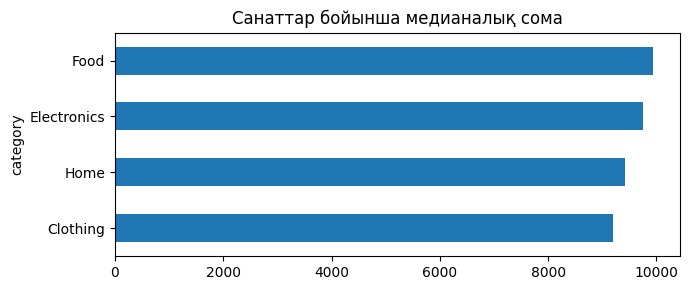

In [ ]:
print('Көрнекі тексеру'); fig,ax=plt.subplots(figsize=(7,3)); work.groupby('category')['amount'].median().sort_values().plot.barh(ax=ax); ax.set_title('Санаттар бойынша медианалық сома');plt.tight_layout();plt.show()

In [ ]:
# Веб-скрапинг және robots.txt: тексерілетін көрсеткіштер
print('Жазбалар:',len(df),'| Бос мәндер:',int(df.isna().sum().sum()))
print('Сома медианасы:',round(df.amount.median(),2),'| Орташа:',round(df.amount.mean(),2))

Жазбалар: 8000 | Бос мәндер: 120
Сома медианасы: 9550.05 | Орташа: 13335.69


In [ ]:
# Веб-скрапинг және robots.txt: топтар арасындағы сандық айырмашылық
g=df.groupby('city').amount.agg(['count','mean','median','std']).round(2);display(g)
print('Макс/мин орташа қатынасы:',round(g['mean'].max()/g['mean'].min(),3))

,count,mean,median,std
city,,,,
Almaty,2008,13628.25,9770.33,13349.86
Astana,1954,13204.09,9599.80,12420.88
Karaganda,2023,13214.29,9136.91,12940.66
Shymkent,2015,13293.64,9780.91,12558.36


Макс/мин орташа қатынасы: 1.032


In [ ]:
# Веб-скрапинг және robots.txt: нәтижені сақтау және қайталанғыштық
result=df.groupby('category',as_index=False).agg(n=('order_id','size'),avg_amount=('amount','mean'))
result.to_csv('reports/lab02_task4.csv',index=False)
print('Сақталды: reports/lab02_task4.csv');display(result)

Сақталды: reports/lab02_task4.csv


,category,n,avg_amount
0,Clothing,1950,13111.903395
1,Electronics,2032,13552.206649
2,Food,2023,13291.850035
3,Home,1995,13378.347860


## 5-тапсырма. Merge: inner, left, outer

**Мақсат:** merge: inner, left, outer әдісін практикалық деректермен көрсету. Кодтарды ретімен орындаңыз.

In [ ]:
a=df[['order_id','customer_id']].head(50);b=df[['order_id','amount']].head(40);display(a.merge(b,on='order_id',how='outer',indicator=True)['_merge'].value_counts())

,count
_merge,
both,40
left_only,10
right_only,0


In [ ]:
work=df.copy(); print('Жол/баған:',work.shape); display(work.head(4))

Жол/баған: (8000, 15)


,order_id,customer_id,product_id,date,city,category,quantity,unit_price,discount,age,channel,rating,amount,returned,review
0,1,99,20,2025-12-28,Karaganda,Food,6,2886.58,0.05,61.0,app,2,16453.51,0,bad quality slow delivery
1,2,852,22,2025-02-12,Shymkent,Food,5,3761.36,0.10,58.0,app,3,16926.12,0,average product delivery
2,3,721,9,2024-01-29,Shymkent,Home,2,2056.07,0.00,42.0,store,4,4112.14,0,great quality fast delivery
3,4,483,11,2025-10-17,Astana,Clothing,6,4272.71,0.20,30.0,web,3,20509.01,0,average product delivery


In [ ]:
# Merge: inner, left, outer: тексерілетін көрсеткіштер
print('Жазбалар:',len(df),'| Бос мәндер:',int(df.isna().sum().sum()))
print('Сома медианасы:',round(df.amount.median(),2),'| Орташа:',round(df.amount.mean(),2))

Жазбалар: 8000 | Бос мәндер: 120


In [ ]:
# Merge: inner, left, outer: топтар арасындағы сандық айырмашылық
g=df.groupby('city').amount.agg(['count','mean','median','std']).round(2);display(g)
print('Макс/мин орташа қатынасы:',round(g['mean'].max()/g['mean'].min(),3))

,count,mean,median,std
city,,,,
Almaty,2008,13628.25,9770.33,13349.86
Astana,1954,13204.09,9599.80,12420.88
Karaganda,2023,13214.29,9136.91,12940.66
Shymkent,2015,13293.64,9780.91,12558.36


In [ ]:
# Merge: inner, left, outer: нәтижені сақтау және қайталанғыштық
result=df.groupby('category',as_index=False).agg(n=('order_id','size'),avg_amount=('amount','mean'))
result.to_csv('reports/lab02_task5.csv',index=False)
print('Сақталды: reports/lab02_task5.csv');display(result)

Сақталды: reports/lab02_task5.csv


,category,n,avg_amount
0,Clothing,1950,13111.903395
1,Electronics,2032,13552.206649
2,Food,2023,13291.850035
3,Home,1995,13378.347860


## 6-тапсырма. ETL және Parquet

**Мақсат:** etl және parquet әдісін практикалық деректермен көрсету. Кодтарды ретімен орындаңыз.

In [ ]:
df.to_parquet('data/processed/etl.parquet',index=False);print('ETL нәтижесі сақталды')

ETL нәтижесі сақталды


In [ ]:
print('Типтер және бос мәндер'); display(pd.DataFrame({'type':work.dtypes.astype(str),'missing':work.isna().sum(),'unique':work.nunique()}))

Типтер және бос мәндер


,type,missing,unique
order_id,int64,0,8000
customer_id,int64,0,1099
product_id,int64,0,30
date,datetime64[ns],0,730
city,object,0,4
category,object,0,4
quantity,int64,0,6
unit_price,float64,0,7946
discount,float64,0,4
age,float64,120,53


In [ ]:
# ETL және Parquet: тексерілетін көрсеткіштер
print('Жазбалар:',len(df),'| Бос мәндер:',int(df.isna().sum().sum()))
print('Сома медианасы:',round(df.amount.median(),2),'| Орташа:',round(df.amount.mean(),2))

Жазбалар: 8000 | Бос мәндер: 120
Сома медианасы: 9550.05 | Орташа: 13335.69


In [ ]:
# ETL және Parquet: топтар арасындағы сандық айырмашылық
g=df.groupby('city').amount.agg(['count','mean','median','std']).round(2);display(g)
print('Макс/мин орташа қатынасы:',round(g['mean'].max()/g['mean'].min(),3))

,count,mean,median,std
city,,,,
Almaty,2008,13628.25,9770.33,13349.86
Astana,1954,13204.09,9599.80,12420.88
Karaganda,2023,13214.29,9136.91,12940.66
Shymkent,2015,13293.64,9780.91,12558.36


Макс/мин орташа қатынасы: 1.032


In [ ]:
# ETL және Parquet: нәтижені сақтау және қайталанғыштық
result=df.groupby('category',as_index=False).agg(n=('order_id','size'),avg_amount=('amount','mean'))
result.to_csv('reports/lab02_task6.csv',index=False)
print('Сақталды: reports/lab02_task6.csv');display(result)

Сақталды: reports/lab02_task6.csv


,category,n,avg_amount
0,Clothing,1950,13111.903395
1,Electronics,2032,13552.206649
2,Food,2023,13291.850035
3,Home,1995,13378.347860


In [ ]:
df.head(50).to_csv('data/raw/semicolon.csv',sep=';',index=False,encoding='utf-8-sig');df.head(50).to_excel('data/raw/example.xlsx',sheet_name='Orders',index=False);json.dump([{'id':1,'meta':{'city':'Almaty'}}],open('data/raw/nested.json','w'))
print(pd.read_csv('data/raw/semicolon.csv',sep=';').shape);print(pd.read_excel('data/raw/example.xlsx').shape);display(pd.json_normalize(json.load(open('data/raw/nested.json'))))
con=sqlite3.connect('data/shop.db');df[['order_id','customer_id','product_id','date','amount']].assign(date=lambda x:x.date.astype(str)).to_sql('orders',con,if_exists='replace',index=False)
df[['customer_id','city','age']].drop_duplicates('customer_id').to_sql('customers',con,if_exists='replace',index=False)
df[['product_id','category']].drop_duplicates('product_id').to_sql('products',con,if_exists='replace',index=False)
queries={'JOIN':"SELECT c.city,COUNT(*) n FROM orders o JOIN customers c USING(customer_id) GROUP BY c.city",'HAVING':"SELECT customer_id,COUNT(*) n FROM orders GROUP BY customer_id HAVING COUNT(*)>5 LIMIT 10",'SUBQUERY':"SELECT * FROM orders WHERE amount>(SELECT AVG(amount) FROM orders) LIMIT 5",'CTE+WINDOW':"WITH monthly AS (SELECT substr(date,1,7) month,SUM(amount) revenue FROM orders GROUP BY 1) SELECT month,revenue,LAG(revenue) OVER(ORDER BY month) previous,ROW_NUMBER() OVER(ORDER BY revenue DESC) rn,RANK() OVER(ORDER BY revenue DESC) rnk,AVG(revenue) OVER(ORDER BY month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) moving_avg FROM monthly"}
for name,q in queries.items():print(name);display(pd.read_sql(q,con).head())
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from urllib.robotparser import RobotFileParser
session=requests.Session();session.mount('https://',HTTPAdapter(max_retries=Retry(total=2,backoff_factor=.5,status_forcelist=[429,500,502,503])))
try:
 api=session.get('https://jsonplaceholder.typicode.com/posts',params={'_page':1,'_limit':5},timeout=8);api.raise_for_status();api_df=pd.DataFrame(api.json());print('API:',api_df.shape)
except requests.RequestException as e: print('Желі қолжетімсіз, API нәтижесі жоқ:',str(e)[:120]);api_df=pd.DataFrame()
url='https://example.com/';rp=RobotFileParser();rp.set_url(url+'robots.txt')
try:
 rp.read()
 if rp.can_fetch('ColabResearchBot',url):
  time.sleep(1);res=session.get(url,timeout=8);res.raise_for_status();print('Web title:',BeautifulSoup(res.text,'html.parser').title.get_text())
 else:print('robots.txt рұқсат бермейді')
except Exception as e:print('Веб-скрапинг желіге байланысты орындалмады:',str(e)[:100])
left=df[['order_id','customer_id']].head(100);right=df[['customer_id','city']].drop_duplicates('customer_id');
for how in ['inner','left','outer']:
 merged=left.merge(right,on='customer_id',how=how,validate='many_to_one',indicator=True);print(how,len(merged),merged._merge.value_counts().to_dict())
# one_to_many тек сол жақ кілт бірегей болғанда жарамды
print('one_to_many:',len(right.merge(left,on='customer_id',validate='one_to_many')))
logging.basicConfig(level=logging.INFO)
open('src/etl.py','w').write("""import pandas as pd
import logging
def extract(path):
 logging.info("Extract %s",path); return pd.read_csv(path)
def transform(df):
 return df.drop_duplicates().copy()
def load(df,path):
 df.to_parquet(path,index=False)
""")
from src.etl import extract,transform,load
load(transform(extract('data/raw/dataset.csv')),'data/processed/etl.parquet')

(50, 15)
(50, 15)


,id,meta.city
0,1,Almaty


JOIN


,city,n
0,Almaty,2113
1,Astana,2080
2,Karaganda,1761
3,Shymkent,2046


HAVING


...

SUBQUERY


,order_id,customer_id,product_id,date,amount
0,1,99,20,2025-12-28,16453.51
1,2,852,22,2025-02-12,16926.12
2,4,483,11,2025-10-17,20509.01
3,5,477,29,2025-11-24,29489.46
4,11,580,18,2024-01-16,26907.26


CTE+WINDOW


,month,revenue,previous,rn,rnk,moving_avg
0,2024-01,4928349.65,NaN,3,3,4.928350e+06
1,2024-02,4180979.18,4928349.65,18,18,4.554664e+06
2,2024-03,4596258.46,4180979.18,9,9,4.568529e+06
3,2024-04,4133758.59,4596258.46,19,19,4.303665e+06
4,2024-05,4789844.70,4133758.59,6,6,4.506621e+06


API: (5, 4)
Web title: Example Domain
inner 100 {'both': 100, 'left_only': 0, 'right_only': 0}
left 100 {'both': 100, 'left_only': 0, 'right_only': 0}
outer 1105 {'right_only': 1005, 'both': 100, 'left_only': 0}
one_to_many: 100
